# 🎮 VALORANT Personal Coach

## Notebook 01 — Exploratory Data Analysis

### Objective

This notebook explores one player's VALORANT Competitive match history before
machine-learning modelling.

The EDA focuses on:

- dataset quality and completeness,
- win/loss/draw balance,
- agent and map usage,
- role distribution,
- performance by agent, map, and role,
- Agent × Map patterns,
- K/D, ACS, DDΔ and other performance distributions,
- recent/monthly performance trends,
- and correlations among numerical match statistics.

The final project is **role-aware**. `Role` is derived from the selected
`Agent`. `TRS` may be explored descriptively in this raw-data EDA, but it is
**not intended to be used as a final modelling feature**.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

## 1. Load the dataset


In [2]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name in [
    "notebooks",
    "DEVnotebooks",
    "ANUJnotebooks",
]:
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "competitive_matches.xlsx"
)

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place competitive_matches.xlsx inside the project data/ folder."
    )

Project root: c:\Users\HP\Desktop\valorant_personal_coach
Dataset path: c:\Users\HP\Desktop\valorant_personal_coach\data\competitive_matches.xlsx


In [3]:
df = pd.read_excel(
    DATA_PATH,
    sheet_name="Matches",
    header=1,
)

# Normalize the long raw column names.
df = df.rename(
    columns={
        "DDΔ (Average Damage Delta per Round)": "DDΔ",
        "HS% (Headshot Percentage)": "HS%",
        "ACS (Average Combat Score)": "ACS",
        "TRS (Tracker Score)": "TRS",
    }
)

# Drop helper / source-link columns that contain no match data.
drop_columns = [
    column
    for column in df.columns
    if (
        str(column).startswith("Unnamed:")
        or str(column).startswith("http://")
        or str(column).startswith("https://")
    )
]

df = (
    df
    .drop(columns=drop_columns, errors="ignore")
    .dropna(how="all")
    .copy()
)

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce",
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (304, 22)


,Match id,Date,Map,Placement,Agent,Team Score,Opponent Score,Result,Win Flag,Score Margin,...,Deaths,Assists,K/D,Kills/Round,Deaths/Round,Assists/Round,DDΔ,HS%,ACS,TRS
0,1,2024-11-07,Sunset,6th,Sage,8,13,Loss,0.0,-5,...,16,3,1.000000,0.761905,0.761905,0.142857,-11,0.10,210,578
1,2,2024-11-07,Split,9th,Clove,5,13,Loss,0.0,-8,...,9,2,0.777778,0.388889,0.500000,0.111111,-9,0.10,117,172
2,3,2024-11-08,Pearl,4th,Clove,13,10,Win,1.0,3,...,15,2,1.333333,0.869565,0.652174,0.086957,19,0.09,229,728
3,4,2024-11-08,Sunset,3rd,Sage,9,11,Loss,0.0,-2,...,15,6,0.933333,0.700000,0.750000,0.300000,11,0.05,237,475
4,5,2024-11-09,Haven,7th,Clove,4,13,Loss,0.0,-9,...,16,2,0.562500,0.529412,0.941176,0.117647,-51,0.10,163,146


## 2. Dataset structure

In [4]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("\nColumns:")
print(df.columns.tolist())

Rows: 304
Columns: 22

Columns:
['Match id', 'Date', 'Map', 'Placement', 'Agent', 'Team Score', 'Opponent Score', 'Result', 'Win Flag', 'Score Margin', 'Rounds Played', 'Kills', 'Deaths', 'Assists', 'K/D', 'Kills/Round', 'Deaths/Round', 'Assists/Round', 'DDΔ', 'HS%', 'ACS', 'TRS']


In [5]:
overview = pd.DataFrame(
    {
        "Data Type": df.dtypes.astype(str),
        "Missing Values": df.isna().sum(),
        "Unique Values": df.nunique(dropna=True),
    }
)

display(overview)

,Data Type,Missing Values,Unique Values
Match id,int64,0,304
Date,datetime64[us],0,153
Map,str,0,13
Placement,str,0,10
Agent,str,0,9
Team Score,int64,0,16
Opponent Score,int64,0,16
Result,str,0,3
Win Flag,float64,10,2
Score Margin,int64,0,26


## 3. Data quality checks

These checks verify missing values, duplicate rows, duplicate match IDs,
and the chronological range of the dataset.

In [6]:
quality_summary = pd.DataFrame(
    {
        "Check": [
            "Total rows",
            "Duplicate rows",
            "Duplicate Match IDs",
            "Missing dates",
            "Missing maps",
            "Missing agents",
            "Missing results",
        ],
        "Value": [
            len(df),
            int(df.duplicated().sum()),
            int(df["Match id"].duplicated().sum()),
            int(df["Date"].isna().sum()),
            int(df["Map"].isna().sum()),
            int(df["Agent"].isna().sum()),
            int(df["Result"].isna().sum()),
        ],
    }
)

display(quality_summary)

print(
    "Date range:",
    df["Date"].min(),
    "to",
    df["Date"].max(),
)

,Check,Value
0,Total rows,304
1,Duplicate rows,0
2,Duplicate Match IDs,0
3,Missing dates,0
4,Missing maps,0
5,Missing agents,0
6,Missing results,0


Date range: 2024-11-07 00:00:00 to 2026-09-27 00:00:00


In [7]:
print("Missing values by column:")
display(
    df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing")
)

Missing values by column:


,Missing
Win Flag,10
Match id,0
Map,0
Placement,0
Agent,0
Date,0
Team Score,0
Opponent Score,0
Result,0
Score Margin,0


### Note on `Win Flag`

Draws do not have a binary Win Flag. This is expected because the later
binary modelling target uses **Win = 1** and **Loss = 0**, while draws are
excluded from binary model training.

In [8]:
print("Result counts:")
display(
    df["Result"]
    .value_counts(dropna=False)
    .to_frame("Matches")
)

print("\nWin Flag counts:")
display(
    df["Win Flag"]
    .value_counts(dropna=False)
    .to_frame("Matches")
)

Result counts:


,Matches
Result,
Loss,152
Win,142
Draw,10



Win Flag counts:


,Matches
Win Flag,
0.0,152
1.0,142
NaN,10


## 4. Overall result distribution

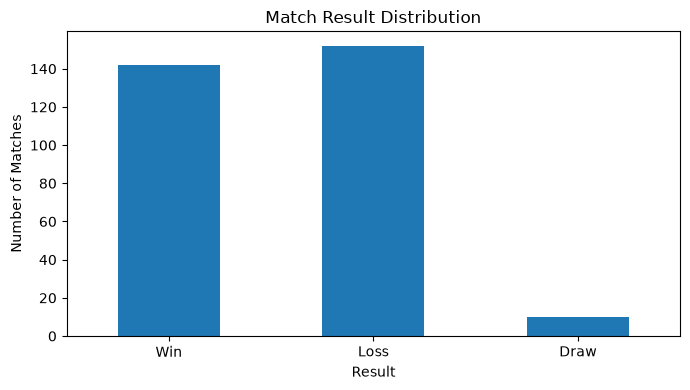

Total matches: 304
Wins: 142
Losses: 152
Draws: 10
Win rate excluding draws: 48.30%


In [9]:
result_counts = (
    df["Result"]
    .value_counts()
    .reindex(["Win", "Loss", "Draw"])
    .dropna()
)

plt.figure(figsize=(7, 4))
result_counts.plot(kind="bar")
plt.title("Match Result Distribution")
plt.xlabel("Result")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

total_matches = len(df)
wins = int((df["Result"] == "Win").sum())
losses = int((df["Result"] == "Loss").sum())
draws = int((df["Result"] == "Draw").sum())

binary_matches = wins + losses
overall_win_rate = (
    wins / binary_matches
    if binary_matches
    else np.nan
)

print("Total matches:", total_matches)
print("Wins:", wins)
print("Losses:", losses)
print("Draws:", draws)
print(
    "Win rate excluding draws:",
    f"{overall_win_rate:.2%}",
)

## 5. Agent usage

,Matches
Agent,
Sage,164
Clove,59
Killjoy,30
Breach,17
Deadlock,11
Skye,9
Astra,6
Fade,5
Reyna,3


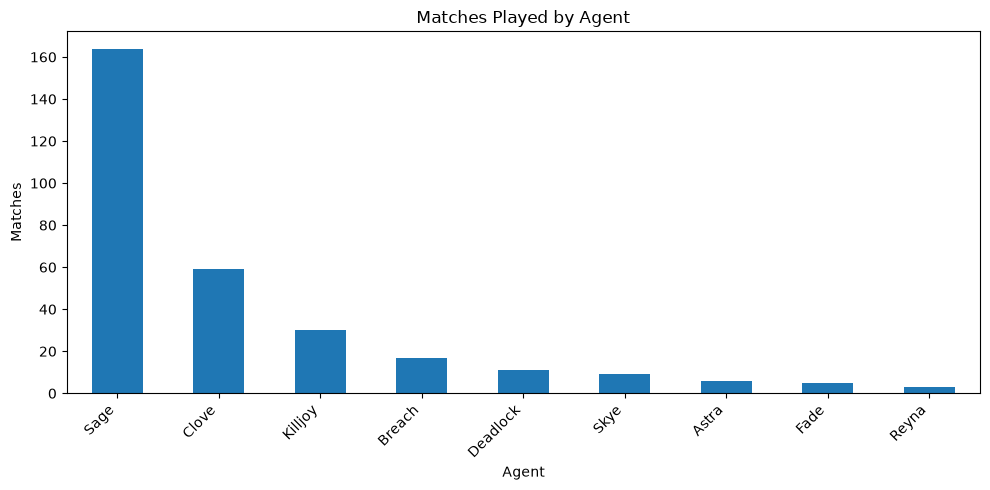

In [10]:
agent_counts = (
    df["Agent"]
    .value_counts()
)

display(
    agent_counts
    .rename("Matches")
    .to_frame()
)

plt.figure(figsize=(10, 5))
agent_counts.plot(kind="bar")
plt.title("Matches Played by Agent")
plt.xlabel("Agent")
plt.ylabel("Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Map usage

,Matches
Map,
Haven,43
Ascent,41
Split,39
Lotus,39
Pearl,34
Sunset,25
Icebox,21
Abyss,17
Fracture,17


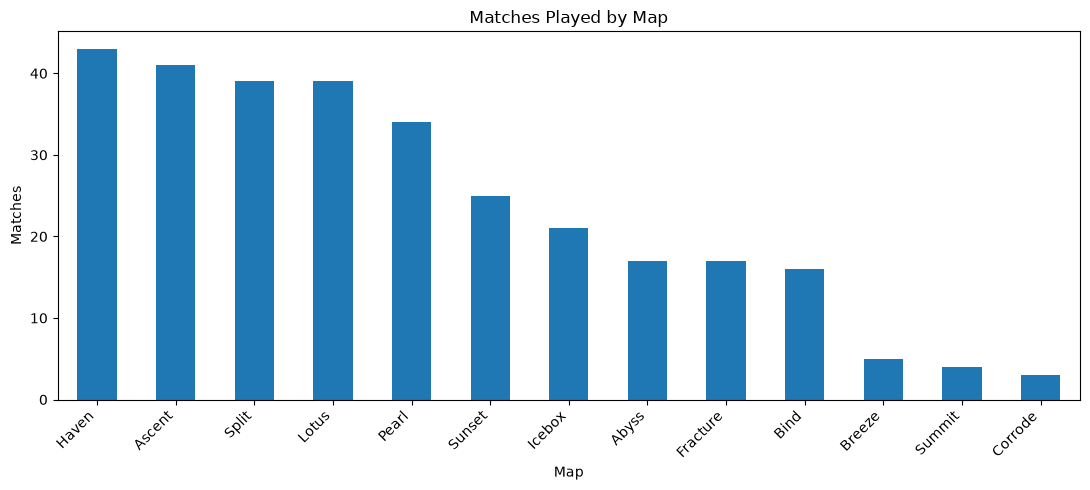

In [11]:
map_counts = (
    df["Map"]
    .value_counts()
)

display(
    map_counts
    .rename("Matches")
    .to_frame()
)

plt.figure(figsize=(11, 5))
map_counts.plot(kind="bar")
plt.title("Matches Played by Map")
plt.xlabel("Map")
plt.ylabel("Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Role-aware EDA

The raw dataset does not contain a Role column, so the official role is
derived directly from Agent identity.

**Agent determines Role. ACS does not determine Role.**

In [12]:
AGENT_ROLE_MAP = {
    # Duelists
    "Iso": "Duelist",
    "Jett": "Duelist",
    "Neon": "Duelist",
    "Phoenix": "Duelist",
    "Raze": "Duelist",
    "Reyna": "Duelist",
    "Waylay": "Duelist",
    "Yoru": "Duelist",

    # Controllers
    "Astra": "Controller",
    "Brimstone": "Controller",
    "Clove": "Controller",
    "Harbor": "Controller",
    "Miks": "Controller",
    "Omen": "Controller",
    "Viper": "Controller",

    # Initiators
    "Breach": "Initiator",
    "Fade": "Initiator",
    "Gekko": "Initiator",
    "KAY/O": "Initiator",
    "Skye": "Initiator",
    "Sova": "Initiator",
    "Tejo": "Initiator",

    # Sentinels
    "Chamber": "Sentinel",
    "Cypher": "Sentinel",
    "Deadlock": "Sentinel",
    "Killjoy": "Sentinel",
    "Sage": "Sentinel",
    "Veto": "Sentinel",
    "Vyse": "Sentinel",
}

df["Role"] = (
    df["Agent"]
    .map(AGENT_ROLE_MAP)
)

unknown_agents = (
    df.loc[
        df["Role"].isna(),
        "Agent",
    ]
    .dropna()
    .unique()
    .tolist()
)

print("Unknown agents:", unknown_agents)
display(
    df["Role"]
    .value_counts(dropna=False)
    .rename("Matches")
    .to_frame()
)

Unknown agents: []


,Matches
Role,
Sentinel,205
Controller,65
Initiator,31
Duelist,3


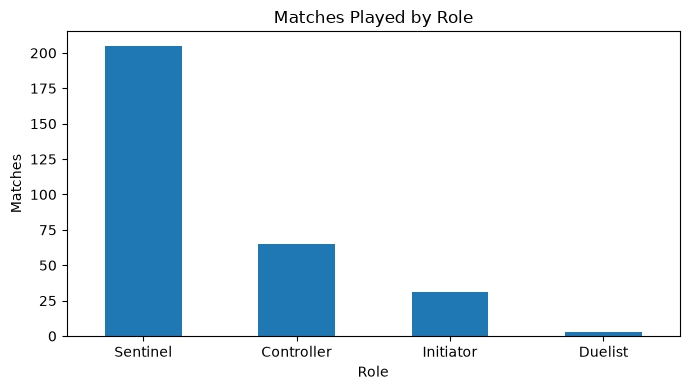

In [13]:
role_counts = (
    df["Role"]
    .value_counts()
)

plt.figure(figsize=(7, 4))
role_counts.plot(kind="bar")
plt.title("Matches Played by Role")
plt.xlabel("Role")
plt.ylabel("Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Performance by Agent

Win rate is calculated using only Win/Loss matches, excluding draws from the
denominator.

In [14]:
binary_df = (
    df[df["Result"].isin(["Win", "Loss"])]
    .copy()
)

binary_df["Win"] = (
    binary_df["Result"] == "Win"
).astype(int)

agent_performance = (
    binary_df
    .groupby("Agent")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
        Avg_DD_Delta=("DDΔ", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    agent_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
            "Avg_DD_Delta": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS,Avg_DD_Delta
Agent,,,,,,
Astra,6,5,83.33%,1.17,142.2,-14.5
Killjoy,30,19,63.33%,1.06,169.6,-8.8
Breach,17,9,52.94%,0.86,157.5,-22.9
Fade,4,2,50.00%,0.92,208.2,-5.5
Clove,57,27,47.37%,0.83,164.7,-36.8
Sage,158,74,46.84%,0.92,156.2,-30.2
Skye,8,3,37.50%,0.83,147.2,-36.8
Reyna,3,1,33.33%,0.85,154.7,-21.7
Deadlock,11,2,18.18%,0.85,163.4,-27.2


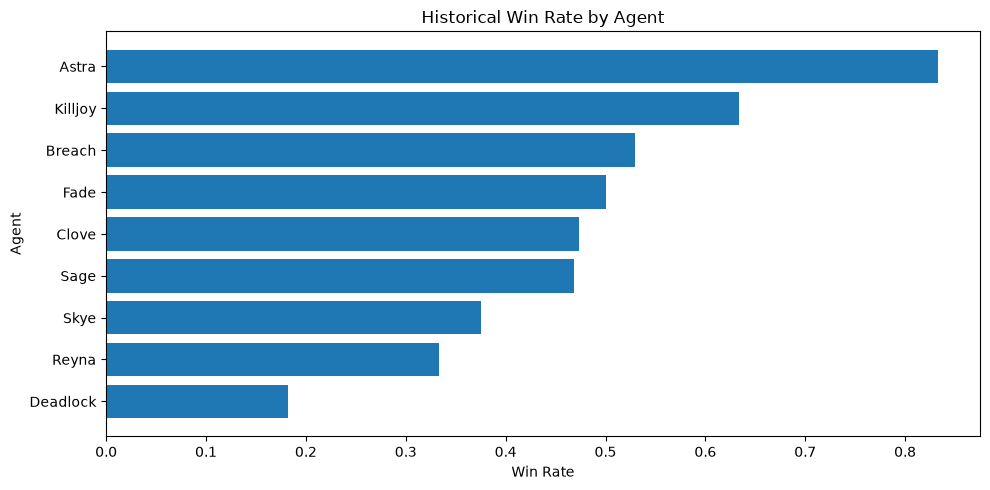

In [15]:
agent_plot = (
    agent_performance
    .sort_values("Win_Rate")
)

plt.figure(figsize=(10, 5))
plt.barh(
    agent_plot.index,
    agent_plot["Win_Rate"],
)
plt.title("Historical Win Rate by Agent")
plt.xlabel("Win Rate")
plt.ylabel("Agent")
plt.tight_layout()
plt.show()

## 9. Performance by Map

In [16]:
map_performance = (
    binary_df
    .groupby("Map")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
        Avg_DD_Delta=("DDΔ", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    map_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
            "Avg_DD_Delta": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS,Avg_DD_Delta
Map,,,,,,
Fracture,16,11,68.75%,0.77,136.4,-32.6
Corrode,3,2,66.67%,0.92,162.3,-22.3
Split,39,23,58.97%,0.91,148.8,-25.0
Haven,41,23,56.10%,0.91,164.0,-22.3
Ascent,39,20,51.28%,1.16,175.3,-16.7
Pearl,33,16,48.48%,0.85,138.6,-37.1
Icebox,19,9,47.37%,0.96,155.1,-31.3
Abyss,17,8,47.06%,0.86,171.1,-24.7
Bind,15,7,46.67%,0.77,161.8,-31.7


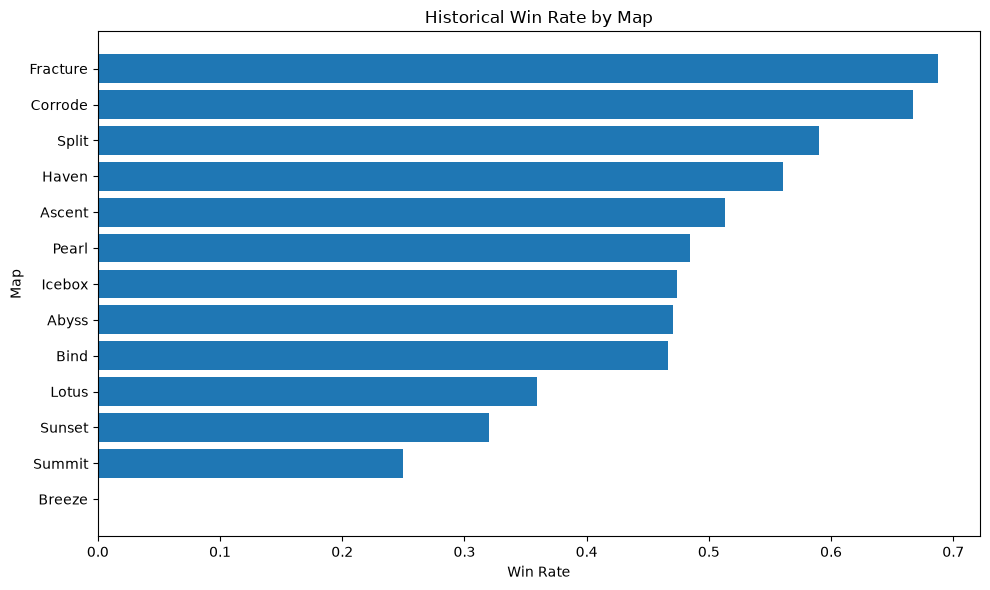

In [17]:
map_plot = (
    map_performance
    .sort_values("Win_Rate")
)

plt.figure(figsize=(10, 6))
plt.barh(
    map_plot.index,
    map_plot["Win_Rate"],
)
plt.title("Historical Win Rate by Map")
plt.xlabel("Win Rate")
plt.ylabel("Map")
plt.tight_layout()
plt.show()

## 10. Performance by Role

In [18]:
role_performance = (
    binary_df
    .groupby("Role")
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

display(
    role_performance.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
Role,,,,,
Controller,63,32,50.79%,0.86,162.5
Initiator,29,14,48.28%,0.86,161.7
Sentinel,199,95,47.74%,0.94,158.6
Duelist,3,1,33.33%,0.85,154.7


## 11. Agent × Map analysis

This table helps identify combinations where the player has historical
experience and stronger results.

Small-sample combinations should be interpreted carefully.

In [19]:
agent_map_performance = (
    binary_df
    .groupby(["Agent", "Map"])
    .agg(
        Matches=("Match id", "count"),
        Wins=("Win", "sum"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
    .reset_index()
    .sort_values(
        ["Matches", "Win_Rate"],
        ascending=[False, False],
    )
)

display(
    agent_map_performance
    .head(30)
    .style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Agent,Map,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
55,Sage,Split,26,16,61.54%,0.95,154.4
53,Sage,Lotus,25,8,32.00%,0.86,159.3
51,Sage,Haven,22,9,40.91%,0.87,152.2
46,Sage,Ascent,21,11,52.38%,1.06,155.5
54,Sage,Pearl,17,7,41.18%,1.04,142.9
52,Sage,Icebox,13,6,46.15%,0.75,156.8
57,Sage,Sunset,11,5,45.45%,1.08,189.5
19,Clove,Haven,10,6,60.00%,0.96,176.0
25,Clove,Sunset,10,1,10.00%,0.66,161.4
41,Killjoy,Split,7,5,71.43%,1.05,165.0


In [20]:
# More stable combinations: at least 5 historical Win/Loss matches.
stable_agent_map = (
    agent_map_performance[
        agent_map_performance["Matches"] >= 5
    ]
    .sort_values(
        ["Win_Rate", "Matches"],
        ascending=[False, False],
    )
)

print(
    "Agent × Map combinations with at least 5 matches:",
    len(stable_agent_map),
)

display(
    stable_agent_map
    .head(20)
    .style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

Agent × Map combinations with at least 5 matches: 19


,Agent,Map,Matches,Wins,Win_Rate,Avg_KD,Avg_ACS
37,Killjoy,Haven,5,5,100.00%,1.06,203.0
13,Clove,Abyss,5,4,80.00%,0.92,176.0
41,Killjoy,Split,7,5,71.43%,1.05,165.0
50,Sage,Fracture,7,5,71.43%,0.78,119.7
55,Sage,Split,26,16,61.54%,0.95,154.4
19,Clove,Haven,10,6,60.00%,0.96,176.0
14,Clove,Ascent,5,3,60.00%,1.27,201.8
46,Sage,Ascent,21,11,52.38%,1.06,155.5
52,Sage,Icebox,13,6,46.15%,0.75,156.8
57,Sage,Sunset,11,5,45.45%,1.08,189.5


## 12. Performance distributions

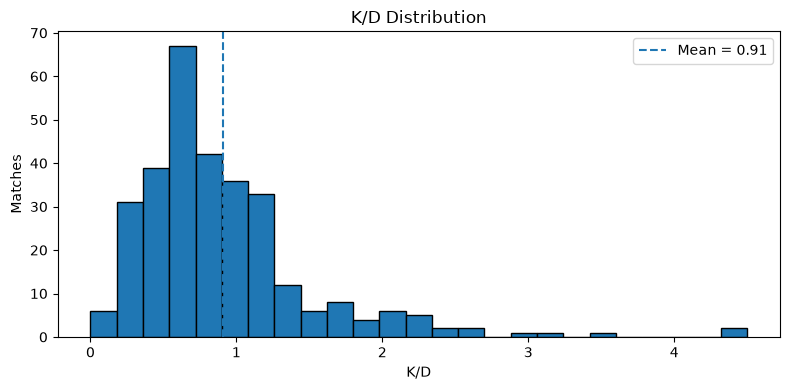

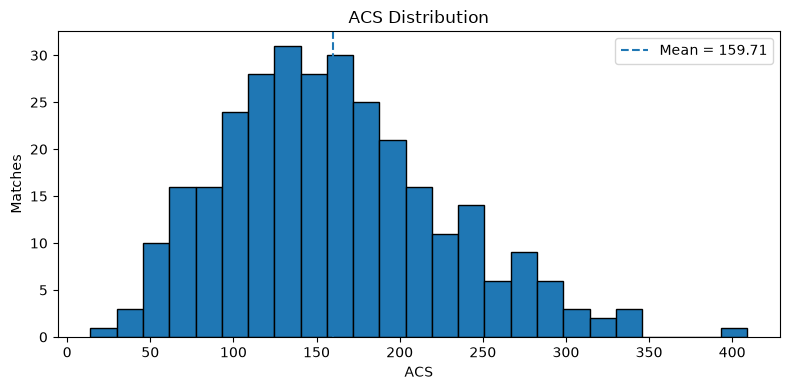

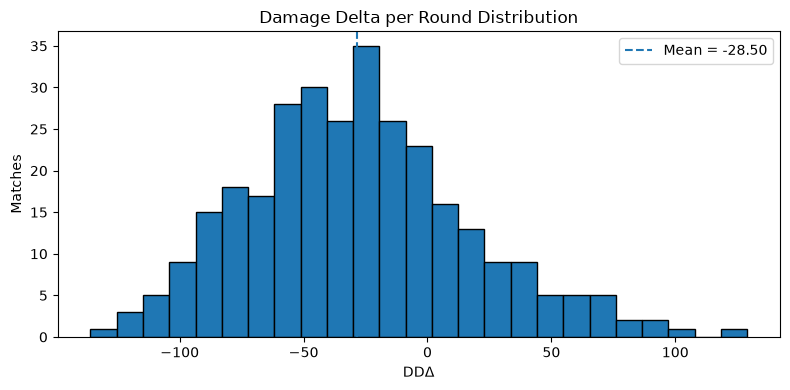

In [21]:
metrics = [
    ("K/D", "K/D Distribution"),
    ("ACS", "ACS Distribution"),
    ("DDΔ", "Damage Delta per Round Distribution"),
]

for column, title in metrics:
    values = pd.to_numeric(
        df[column],
        errors="coerce",
    ).dropna()

    plt.figure(figsize=(8, 4))
    plt.hist(
        values,
        bins=25,
        edgecolor="black",
    )
    plt.axvline(
        values.mean(),
        linestyle="--",
        label=f"Mean = {values.mean():.2f}",
    )
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Matches")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 13. Wins vs Losses performance comparison

In [22]:
comparison_columns = [
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "ACS",
    "DDΔ",
    "HS%",
    "Score Margin",
]

result_comparison = (
    df[df["Result"].isin(["Win", "Loss"])]
    .groupby("Result")[comparison_columns]
    .mean(numeric_only=True)
    .T
)

display(
    result_comparison.style.format("{:.2f}")
)

Result,Loss,Win
Kills,10.30,11.72
Deaths,15.45,11.69
Assists,4.62,5.68
K/D,0.68,1.16
ACS,154.87,164.89
DDΔ,-46.91,-8.12
HS%,0.07,0.07
Score Margin,-5.82,6.01


## 14. Numerical correlations

Correlation is descriptive only. It does not imply causation.

`TRS` is included here only because it exists in the raw dataset. It should
not be used as a final pre-match modelling feature.

In [23]:
correlation_columns = [
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "Kills/Round",
    "Deaths/Round",
    "Assists/Round",
    "DDΔ",
    "HS%",
    "ACS",
    "TRS",
    "Score Margin",
    "Win Flag",
]

correlation_columns = [
    column
    for column in correlation_columns
    if column in df.columns
]

correlation_df = (
    df[correlation_columns]
    .apply(
        pd.to_numeric,
        errors="coerce",
    )
    .corr()
)

display(
    correlation_df.round(2)
)

,Kills,Deaths,Assists,K/D,Kills/Round,Deaths/Round,Assists/Round,DDΔ,HS%,ACS,TRS,Score Margin,Win Flag
Kills,1.00,0.19,0.21,0.57,0.88,-0.06,0.08,0.68,0.08,0.86,0.70,0.10,0.13
Deaths,0.19,1.00,0.21,-0.53,-0.14,0.74,-0.05,-0.46,-0.02,-0.05,-0.37,-0.46,-0.43
Assists,0.21,0.21,1.00,-0.00,0.02,-0.08,0.92,0.11,-0.08,0.09,0.22,0.18,0.19
K/D,0.57,-0.53,-0.00,1.00,0.74,-0.62,0.07,0.83,0.14,0.65,0.79,0.44,0.39
Kills/Round,0.88,-0.14,0.02,0.74,1.00,-0.12,0.03,0.78,0.10,0.97,0.78,0.13,0.15
Deaths/Round,-0.06,0.74,-0.08,-0.62,-0.12,1.00,-0.15,-0.56,-0.05,-0.01,-0.52,-0.71,-0.61
Assists/Round,0.08,-0.05,0.92,0.07,0.03,-0.15,1.00,0.16,-0.12,0.10,0.26,0.24,0.22
DDΔ,0.68,-0.46,0.11,0.83,0.78,-0.56,0.16,1.00,0.13,0.77,0.89,0.44,0.42
HS%,0.08,-0.02,-0.08,0.14,0.10,-0.05,-0.12,0.13,1.00,0.04,0.06,-0.03,-0.00
ACS,0.86,-0.05,0.09,0.65,0.97,-0.01,0.10,0.77,0.04,1.00,0.74,0.03,0.07


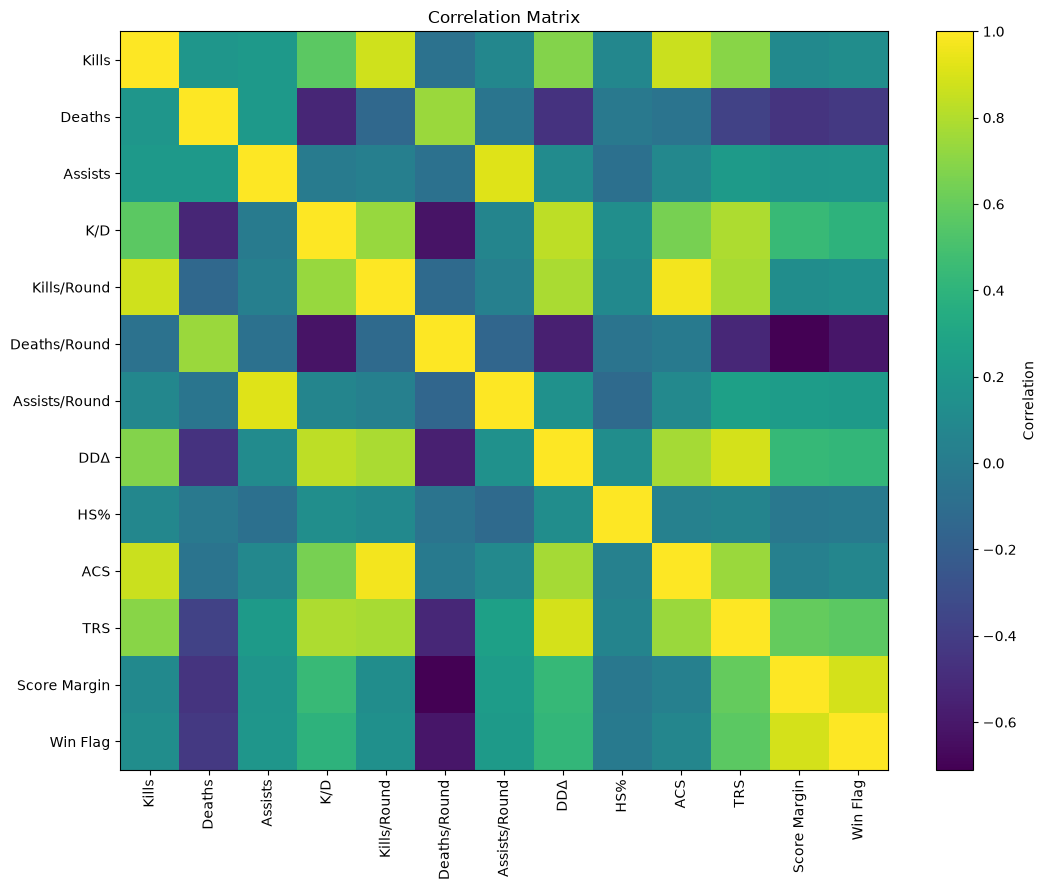

In [24]:
fig, ax = plt.subplots(
    figsize=(11, 9)
)

image = ax.imshow(
    correlation_df.values,
    aspect="auto",
)

ax.set_xticks(
    range(len(correlation_df.columns))
)
ax.set_yticks(
    range(len(correlation_df.index))
)

ax.set_xticklabels(
    correlation_df.columns,
    rotation=90,
)
ax.set_yticklabels(
    correlation_df.index,
)

ax.set_title(
    "Correlation Matrix"
)

fig.colorbar(
    image,
    ax=ax,
    label="Correlation",
)

plt.tight_layout()
plt.show()

## 15. Monthly performance trend

In [25]:
monthly = (
    binary_df
    .set_index("Date")
    .resample("MS")
    .agg(
        Matches=("Match id", "count"),
        Win_Rate=("Win", "mean"),
        Avg_KD=("K/D", "mean"),
        Avg_ACS=("ACS", "mean"),
    )
)

monthly = monthly[
    monthly["Matches"] > 0
]

display(
    monthly.style.format(
        {
            "Win_Rate": "{:.2%}",
            "Avg_KD": "{:.2f}",
            "Avg_ACS": "{:.1f}",
        }
    )
)

,Matches,Win_Rate,Avg_KD,Avg_ACS
Date,,,,
2024-11-01 00:00:00,22,36.36%,0.72,145.6
2024-12-01 00:00:00,6,50.00%,0.70,168.3
2025-01-01 00:00:00,14,64.29%,0.60,114.3
2025-02-01 00:00:00,29,48.28%,0.83,133.7
2025-03-01 00:00:00,48,43.75%,0.92,161.4
2025-04-01 00:00:00,42,59.52%,1.00,157.4
2025-05-01 00:00:00,19,52.63%,0.70,122.2
2025-06-01 00:00:00,32,50.00%,1.00,164.8
2025-07-01 00:00:00,13,38.46%,0.80,161.1


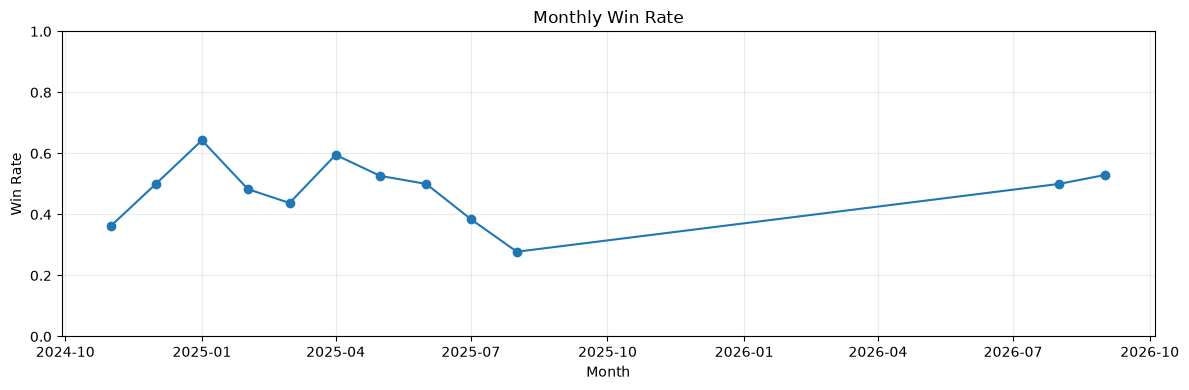

In [26]:
plt.figure(figsize=(12, 4))
plt.plot(
    monthly.index,
    monthly["Win_Rate"],
    marker="o",
)
plt.title("Monthly Win Rate")
plt.xlabel("Month")
plt.ylabel("Win Rate")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 16. Highest and lowest K/D matches

In [27]:
display_columns = [
    "Date",
    "Map",
    "Agent",
    "Role",
    "Result",
    "Kills",
    "Deaths",
    "Assists",
    "K/D",
    "ACS",
    "DDΔ",
]

print("Highest K/D matches:")
display(
    df.nlargest(
        10,
        "K/D",
    )[display_columns]
)

print("\nLowest K/D matches:")
display(
    df.nsmallest(
        10,
        "K/D",
    )[display_columns]
)

Highest K/D matches:


,Date,Map,Agent,Role,Result,Kills,Deaths,Assists,K/D,ACS,DDΔ
117,2025-03-30,Ascent,Sage,Sentinel,Win,9,2,3,4.500000,182,65
139,2025-04-15,Ascent,Killjoy,Sentinel,Win,13,3,3,4.333333,290,77
62,2025-02-24,Pearl,Sage,Sentinel,Win,7,2,3,3.500000,128,45
255,2026-08-11,Ascent,Clove,Controller,Win,16,5,5,3.200000,277,73
148,2025-04-18,Icebox,Astra,Controller,Win,3,1,0,3.000000,81,13
285,2026-08-30,Haven,Sage,Sentinel,Win,32,12,8,2.666667,409,129
250,2026-08-08,Sunset,Sage,Sentinel,Win,21,8,4,2.625000,248,44
251,2026-08-08,Haven,Clove,Controller,Win,19,8,6,2.375000,314,90
275,2026-08-27,Sunset,Sage,Sentinel,Win,26,11,11,2.363636,302,84
162,2025-04-27,Split,Killjoy,Sentinel,Win,21,9,3,2.333333,237,70



Lowest K/D matches:


,Date,Map,Agent,Role,Result,Kills,Deaths,Assists,K/D,ACS,DDΔ
58,2025-02-22,Pearl,Deadlock,Sentinel,Loss,0,18,4,0.000000,14,-136
137,2025-04-12,Pearl,Killjoy,Sentinel,Win,2,15,3,0.133333,32,-83
201,2025-06-20,Icebox,Sage,Sentinel,Loss,3,22,5,0.136364,47,-100
35,2025-01-08,Pearl,Sage,Sentinel,Loss,3,18,2,0.166667,46,-114
37,2025-01-11,Split,Sage,Sentinel,Loss,2,12,6,0.166667,69,-87
80,2025-03-11,Split,Sage,Sentinel,Loss,3,17,9,0.176471,74,-88
47,2025-02-19,Fracture,Sage,Sentinel,Loss,2,11,2,0.181818,62,-113
145,2025-04-16,Haven,Sage,Sentinel,Win,2,11,9,0.181818,53,-82
166,2025-05-03,Pearl,Sage,Sentinel,Loss,3,16,7,0.187500,88,-81
225,2025-07-23,Ascent,Clove,Controller,Loss,3,16,6,0.187500,92,-81


## 17. EDA Summary

This dataset provides enough historical information to study personalized
patterns across **agents, maps, roles, recent form, and Agent × Map
combinations**.

Key modelling implications:

1. Agent usage is not uniform, so recommendation confidence will be higher
   for frequently played agents than rarely played agents.
2. Map experience varies, so historical map features should be included.
3. Role usage is imbalanced, which motivates the final **Top 2 agents per
   role** recommendation layer.
4. Current-match combat statistics such as K/D, ACS, kills, deaths, DDΔ and
   TRS are useful for EDA, but the final ML model must use only their
   **historical pre-match summaries** to avoid data leakage.
5. Agent × Map combinations with very few matches should be interpreted with
   caution because their observed win rates are unstable.

The next stage is to run the common cleaning and leakage-free historical
feature-engineering pipeline before training Logistic Regression, Random
Forest, and CatBoost separately.